# Task 5 — Ensemble Learning, Model Optimization & Real-World ML Pipeline

**Dataset:** Breast Cancer Wisconsin (loaded via `sklearn.datasets.load_breast_cancer`)
**Author:** Gundu Jeevesh Laahiri
**Internship:** Maincrafts Technology — Artificial Intelligence & Machine Learning

## Objective

Build a complete, reproducible classification pipeline that compares a Logistic
Regression baseline with two ensemble methods (Random Forest and Gradient
Boosting), then tune the Random Forest with `GridSearchCV` and perform an
evidence-based final-model selection.

## Positive-class convention

`sklearn.datasets.load_breast_cancer` encodes `target 0 = malignant` and
`target 1 = benign`. Because the clinical screening task is to detect cancer,
this notebook treats **malignant (class 0) as the positive class** whenever
precision, recall and F1 are computed, and `GridSearchCV` is scored with an
F1 scorer configured with `pos_label=0`. Accuracy and ROC-AUC are
label-symmetric. "Malignant Recall" is reported explicitly in the summary table.

> ⚠️ *This is an educational experiment. It is not a validated clinical
> diagnostic system and must not be used for real medical decisions.*

## 1. Environment & library versions

Record the exact versions of the libraries used so that the experiment can
be reproduced later.

In [1]:
import sys, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print(f"Python       : {sys.version.split()[0]}")
print(f"Platform     : {platform.platform()}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")
print(f"seaborn      : {sns.__version__}")

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
MALIGNANT, BENIGN = 0, 1

Python       : 3.12.3
Platform     : Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
numpy        : 2.4.4
pandas       : 3.0.2
scikit-learn : 1.8.0
matplotlib   : 3.10.8
seaborn      : 0.13.2


In [2]:
# Imports used throughout the notebook
import json, time
from pathlib import Path

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold, cross_val_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix,
    classification_report, make_scorer,
)

FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path('results'); RES_DIR.mkdir(exist_ok=True)

## 2. Load the dataset

The Breast Cancer Wisconsin (Diagnostic) dataset is bundled with scikit-learn.
It contains 569 observations, 30 numeric features derived from fine-needle
aspirate images and a binary malignant/benign target.

In [3]:
dataset = load_breast_cancer()
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name='target')

print('Shape        :', X.shape)
print('Target names :', list(dataset.target_names))
X.head()

Shape        : (569, 30)
Target names : [np.str_('malignant'), np.str_('benign')]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### 2.1 Verify the target mapping

Treating the wrong class as positive would quietly inflate recall for the
healthy class and understate the clinically important malignant recall, so
we assert the mapping explicitly before continuing.

In [4]:
assert dataset.target_names[0] == 'malignant'
assert dataset.target_names[1] == 'benign'
print('Target mapping: 0 = malignant, 1 = benign (verified).')

Target mapping: 0 = malignant, 1 = benign (verified).


### 2.2 Data quality & class distribution

In [5]:
print('Missing cells  :', int(X.isna().sum().sum()))
print('Duplicate rows :', int(X.duplicated().sum()))
print('Feature dtypes :', X.dtypes.unique())

class_labels = {0: 'malignant', 1: 'benign'}
counts = y.value_counts().sort_index()
for cls, n in counts.items():
    print(f'  {cls} ({class_labels[cls]:>9}): {n:>4}  ({n/len(y):.1%})')

Missing cells  : 0
Duplicate rows : 0
Feature dtypes : [dtype('float64')]
  0 (malignant):  212  (37.3%)
  1 (   benign):  357  (62.7%)


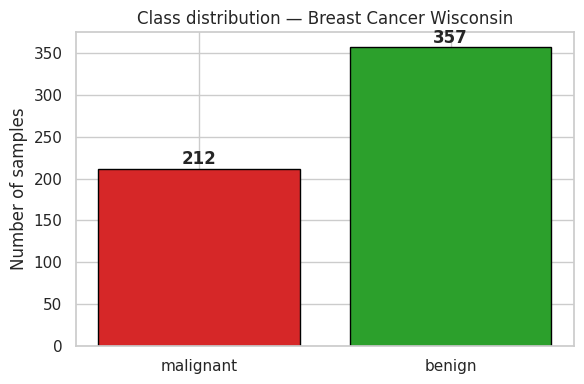

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(
    [class_labels[c] for c in counts.index],
    counts.values,
    color=['#d62728', '#2ca02c'],  # malignant red, benign green
    edgecolor='black',
)
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha='center', fontweight='bold')
ax.set_title('Class distribution — Breast Cancer Wisconsin')
ax.set_ylabel('Number of samples')
fig.tight_layout()
fig.savefig(FIG_DIR / 'class_distribution.png', dpi=150)
plt.show()

The dataset is moderately imbalanced (~37% malignant / 63% benign). Because
false negatives in cancer screening are especially costly, we will keep
stratified splits and focus evaluation on malignant precision/recall/F1 in
addition to overall accuracy.

### 2.3 Descriptive statistics (first eight features)

In [7]:
X.iloc[:, :8].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201


## 3. Train/test split

An 80/20 stratified split with `random_state=42` is created **before** any
preprocessing is fit, so no information leaks from the test set into scaling
or model selection.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y,
)
print('X_train:', X_train.shape, '  X_test:', X_test.shape)
print('Train class ratio:', dict(y_train.value_counts(normalize=True).round(3).sort_index()))
print('Test  class ratio:', dict(y_test.value_counts(normalize=True).round(3).sort_index()))

X_train: (455, 30)   X_test: (114, 30)
Train class ratio: {0: np.float64(0.374), 1: np.float64(0.626)}
Test  class ratio: {0: np.float64(0.368), 1: np.float64(0.632)}


## 4. Evaluation helper

A single helper computes every reported metric so that each model is
evaluated under identical definitions. The precision/recall/F1 numbers in
the returned dict always refer to the **malignant class (pos_label=0)**.

In [9]:
def evaluate(name, model, X_eval, y_eval, fit_time):
    '''Return the metric dict used throughout the comparison table.'''
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)
    mal_col = list(model.classes_).index(MALIGNANT)
    y_proba_mal = y_proba[:, mal_col]

    acc    = accuracy_score(y_eval, y_pred)
    prec_m = precision_score(y_eval, y_pred, pos_label=MALIGNANT)
    rec_m  = recall_score(y_eval, y_pred, pos_label=MALIGNANT)
    f1_m   = f1_score(y_eval, y_pred, pos_label=MALIGNANT)
    auc    = roc_auc_score((y_eval == MALIGNANT).astype(int), y_proba_mal)
    cm     = confusion_matrix(y_eval, y_pred, labels=[MALIGNANT, BENIGN])

    print(f'\n[{name}]  fit_time={fit_time:.3f}s')
    print(f'  accuracy             : {acc:.4f}')
    print(f'  precision (malignant): {prec_m:.4f}')
    print(f'  recall    (malignant): {rec_m:.4f}')
    print(f'  F1        (malignant): {f1_m:.4f}')
    print(f'  ROC-AUC              : {auc:.4f}')
    print('  confusion matrix (rows=actual, cols=predicted, order=[malignant, benign]):')
    print('   ', cm.tolist())
    print(classification_report(y_eval, y_pred, target_names=['malignant(0)', 'benign(1)']))

    return {
        'model': name,
        'accuracy': acc,
        'precision_malignant': prec_m,
        'recall_malignant':    rec_m,
        'f1_malignant':        f1_m,
        'roc_auc':             auc,
        'malignant_recall':    rec_m,
        'fit_time_sec':        fit_time,
        'y_pred':              y_pred,
        'y_proba_mal':         y_proba_mal,
        'confusion_matrix':    cm,
    }

## 5. Baseline — Logistic Regression

Logistic Regression is sensitive to feature scale because its coefficients
are compared on a common scale during optimisation. We therefore wrap a
`StandardScaler` and the classifier in a `Pipeline` so that the scaler is
fit *only on the training folds* during cross-validation — eliminating
train/test leakage.

In [10]:
lr_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])
t0 = time.perf_counter()
lr_pipeline.fit(X_train, y_train)
lr_fit = time.perf_counter() - t0
lr_metrics = evaluate('LogisticRegression', lr_pipeline, X_test, y_test, lr_fit)


[LogisticRegression]  fit_time=0.006s
  accuracy             : 0.9825
  precision (malignant): 0.9762
  recall    (malignant): 0.9762
  F1        (malignant): 0.9762
  ROC-AUC              : 0.9954
  confusion matrix (rows=actual, cols=predicted, order=[malignant, benign]):
    [[41, 1], [1, 71]]
              precision    recall  f1-score   support

malignant(0)       0.98      0.98      0.98        42
   benign(1)       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## 6. Random Forest (default settings)

A Random Forest aggregates many decision trees grown on bootstrap samples
of the training data and random feature subsets. The averaging reduces
variance relative to a single tree and typically generalises well on
tabular data. Tree-based models do **not** need standard feature scaling,
because each split threshold is evaluated on a single feature at a time.

In [11]:
rf = RandomForestClassifier(random_state=RANDOM_STATE)
t0 = time.perf_counter()
rf.fit(X_train, y_train)
rf_fit = time.perf_counter() - t0
rf_metrics = evaluate('RandomForest (default)', rf, X_test, y_test, rf_fit)


[RandomForest (default)]  fit_time=0.180s
  accuracy             : 0.9561
  precision (malignant): 0.9512
  recall    (malignant): 0.9286
  F1        (malignant): 0.9398
  ROC-AUC              : 0.9937
  confusion matrix (rows=actual, cols=predicted, order=[malignant, benign]):
    [[39, 3], [2, 70]]
              precision    recall  f1-score   support

malignant(0)       0.95      0.93      0.94        42
   benign(1)       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## 7. Gradient Boosting

Gradient Boosting trains shallow trees sequentially, each new tree fitted to
the residual errors of the current ensemble. It often achieves strong
accuracy at the cost of being more sensitive to hyperparameters and
training longer than a Random Forest.

In [12]:
gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
t0 = time.perf_counter()
gb.fit(X_train, y_train)
gb_fit = time.perf_counter() - t0
gb_metrics = evaluate('GradientBoosting', gb, X_test, y_test, gb_fit)


[GradientBoosting]  fit_time=0.369s
  accuracy             : 0.9561
  precision (malignant): 0.9744
  recall    (malignant): 0.9048
  F1        (malignant): 0.9383
  ROC-AUC              : 0.9907
  confusion matrix (rows=actual, cols=predicted, order=[malignant, benign]):
    [[38, 4], [1, 71]]
              precision    recall  f1-score   support

malignant(0)       0.97      0.90      0.94        42
   benign(1)       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## 8. Hyperparameter tuning — `GridSearchCV` on Random Forest

The grid covers the Random Forest hyperparameters most likely to affect
bias/variance:

| Parameter           | Values                | Effect                                          |
|---------------------|-----------------------|-------------------------------------------------|
| `n_estimators`      | 100, 200, 400         | More trees ⇒ more stable predictions, higher cost |
| `max_depth`         | None, 5, 10           | Depth cap controls per-tree complexity (variance) |
| `min_samples_split` | 2, 5                  | Larger ⇒ fewer, more conservative splits        |
| `min_samples_leaf`  | 1, 2                  | Larger ⇒ smoother leaves, less overfitting      |

Scoring uses `f1_score` with `pos_label=0`, i.e. the **malignant** class,
which matches the clinical priority of the task. Cross-validation is 5-fold
stratified so each fold preserves the class ratio. The entire search uses
only the training set — the test set remains untouched until the final
evaluation.

In [13]:
param_grid = {
    'n_estimators':      [100, 200, 400],
    'max_depth':         [None, 5, 10],
    'min_samples_split': [2, 5],
    'min_samples_leaf':  [1, 2],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
malignant_f1_scorer = make_scorer(f1_score, pos_label=MALIGNANT)

grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring=malignant_f1_scorer,
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=False,
)

t0 = time.perf_counter()
grid.fit(X_train, y_train)
grid_fit_time = time.perf_counter() - t0

print(f'GridSearchCV completed in {grid_fit_time:.1f}s')
print('Best parameters :', grid.best_params_)
print(f'Best CV F1(mal) : {grid.best_score_:.4f}')

cv_results = pd.DataFrame(grid.cv_results_)
best_idx = int(grid.best_index_)
print(
    f'Best CV mean    : {cv_results.loc[best_idx, "mean_test_score"]:.4f}  '
    f'std = {cv_results.loc[best_idx, "std_test_score"]:.4f}'
)

cv_results_slim = cv_results[
    ['params', 'mean_test_score', 'std_test_score', 'mean_fit_time', 'rank_test_score']
].sort_values('rank_test_score')
cv_results_slim.to_csv(RES_DIR / 'random_forest_cv_results.csv', index=False)
cv_results_slim.head(8)

GridSearchCV completed in 66.4s
Best parameters : {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best CV F1(mal) : 0.9506
Best CV mean    : 0.9506  std = 0.0230


,params,mean_test_score,std_test_score,mean_fit_time,rank_test_score
0,"{'max_depth': None, 'min_samples_leaf': 1, 'mi...",0.950604,0.022990,0.141613,1
24,"{'max_depth': 10, 'min_samples_leaf': 1, 'min_...",0.950604,0.022990,0.147345,1
25,"{'max_depth': 10, 'min_samples_leaf': 1, 'min_...",0.950344,0.022929,0.322264,3
1,"{'max_depth': None, 'min_samples_leaf': 1, 'mi...",0.950344,0.022929,0.282063,3
18,"{'max_depth': 5, 'min_samples_leaf': 2, 'min_s...",0.949911,0.023264,0.148976,5
16,"{'max_depth': 5, 'min_samples_leaf': 1, 'min_s...",0.949911,0.023264,0.291837,5
21,"{'max_depth': 5, 'min_samples_leaf': 2, 'min_s...",0.949911,0.023264,0.143554,5
9,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...",0.949808,0.023504,0.160324,8


## 9. Optimized Random Forest — evaluation on the held-out test set

`grid.best_estimator_` was already refit on the full training set. We also
record a fresh single-fit timing for a fair comparison with the untuned
Random Forest.

In [14]:
t0 = time.perf_counter()
best_rf = RandomForestClassifier(random_state=RANDOM_STATE, **grid.best_params_).fit(X_train, y_train)
best_rf_fit = time.perf_counter() - t0
best_rf_metrics = evaluate('RandomForest (optimized)', best_rf, X_test, y_test, best_rf_fit)


[RandomForest (optimized)]  fit_time=0.163s
  accuracy             : 0.9561
  precision (malignant): 0.9512
  recall    (malignant): 0.9286
  F1        (malignant): 0.9398
  ROC-AUC              : 0.9937
  confusion matrix (rows=actual, cols=predicted, order=[malignant, benign]):
    [[39, 3], [2, 70]]
              precision    recall  f1-score   support

malignant(0)       0.95      0.93      0.94        42
   benign(1)       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## 10. Model comparison

All four models are compared on the same held-out test set using the same
metric definitions.

In [15]:
rows = []
for m in [lr_metrics, rf_metrics, gb_metrics, best_rf_metrics]:
    rows.append({
        'Model': m['model'],
        'Accuracy':              round(m['accuracy'], 4),
        'Precision (malignant)': round(m['precision_malignant'], 4),
        'Recall (malignant)':    round(m['recall_malignant'], 4),
        'F1 (malignant)':        round(m['f1_malignant'], 4),
        'ROC-AUC':               round(m['roc_auc'], 4),
        'Malignant Recall':      round(m['malignant_recall'], 4),
        'Fit Time (s)':          round(m['fit_time_sec'], 4),
    })
comparison = pd.DataFrame(rows)
comparison.to_csv(RES_DIR / 'model_comparison.csv', index=False)
comparison

,Model,Accuracy,Precision (malignant),Recall (malignant),F1 (malignant),ROC-AUC,Malignant Recall,Fit Time (s)
0,LogisticRegression,0.9825,0.9762,0.9762,0.9762,0.9954,0.9762,0.0062
1,RandomForest (default),0.9561,0.9512,0.9286,0.9398,0.9937,0.9286,0.1802
2,GradientBoosting,0.9561,0.9744,0.9048,0.9383,0.9907,0.9048,0.3687
3,RandomForest (optimized),0.9561,0.9512,0.9286,0.9398,0.9937,0.9286,0.1635


## 11. Visualisations

### 11.1 Confusion matrices — selected model vs optimized ensemble

The left panel is the **final selected model (Logistic Regression)**. The
right panel is the Optimized Random Forest, shown for comparison because
Phase 7 performed hyperparameter tuning on it. Which model is "selected"
is only decided after the comparison in Section 10, so the plot title
reflects that decision rather than hard-coding one model in advance.

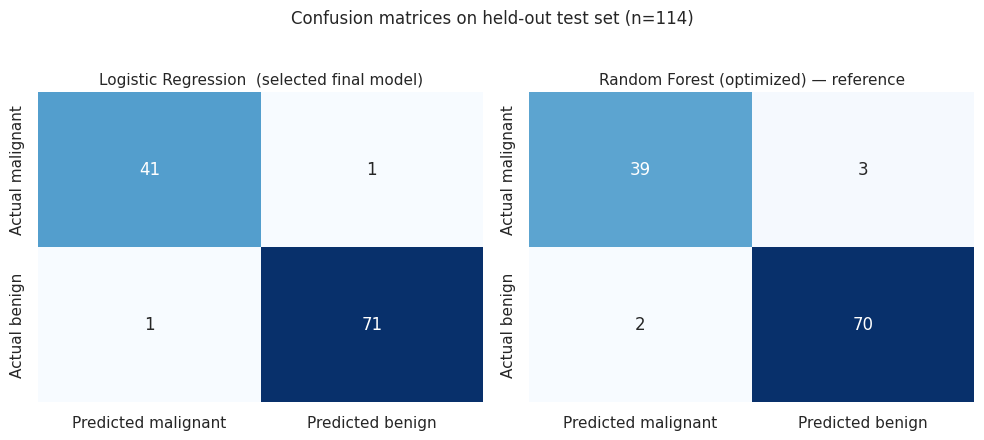

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, mdict, title in [
    (axes[0], lr_metrics,       'Logistic Regression  (selected final model)'),
    (axes[1], best_rf_metrics,  'Random Forest (optimized) — reference'),
]:
    sns.heatmap(
        mdict['confusion_matrix'], annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=['Predicted malignant', 'Predicted benign'],
        yticklabels=['Actual malignant',    'Actual benign'],
        ax=ax,
    )
    ax.set_title(title, fontsize=11)
fig.suptitle('Confusion matrices on held-out test set (n=114)', fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### 11.2 ROC curves — all four models

Curves are drawn with **malignant as the positive class** so the Y-axis is
the fraction of malignant cases correctly flagged.

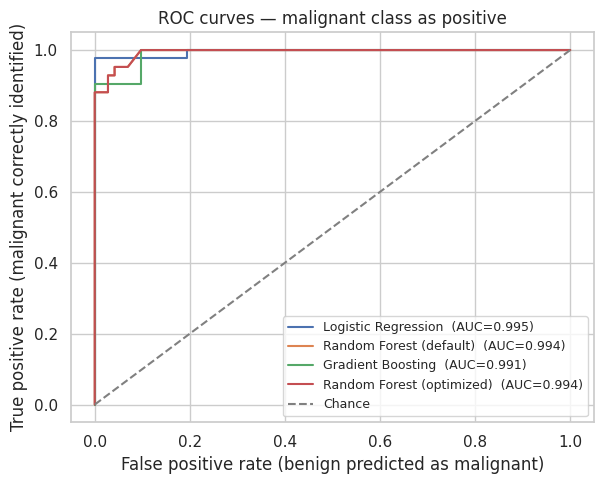

In [17]:
fig, ax = plt.subplots(figsize=(6.2, 5))
for m, label in [
    (lr_metrics,       'Logistic Regression'),
    (rf_metrics,       'Random Forest (default)'),
    (gb_metrics,       'Gradient Boosting'),
    (best_rf_metrics,  'Random Forest (optimized)'),
]:
    fpr, tpr, _ = roc_curve((y_test == MALIGNANT).astype(int), m['y_proba_mal'])
    ax.plot(fpr, tpr, label=f"{label}  (AUC={m['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], '--', color='grey', label='Chance')
ax.set_xlabel('False positive rate (benign predicted as malignant)')
ax.set_ylabel('True positive rate (malignant correctly identified)')
ax.set_title('ROC curves — malignant class as positive')
ax.legend(loc='lower right', fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / 'roc_curves.png', dpi=150)
plt.show()

### 11.3 Feature importance of the optimized Random Forest

Impurity-based feature importances show which features the trees relied on
most for their splits. They indicate model behaviour, not clinical
causation, and should not be used to make medical claims.

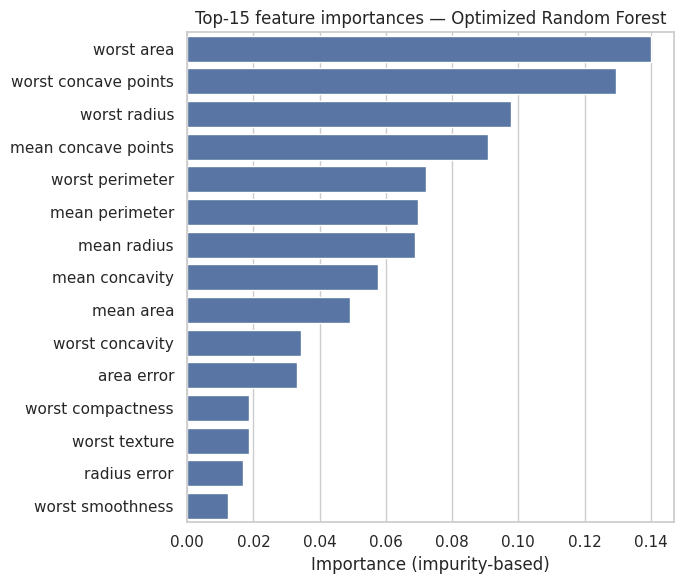

worst area              0.140016
worst concave points    0.129530
worst radius            0.097696
mean concave points     0.090885
worst perimeter         0.072226
mean perimeter          0.069574
mean radius             0.068676
mean concavity          0.057638
mean area               0.049172
worst concavity         0.034340
Name: Feature, dtype: float64

In [18]:
importances = pd.Series(
    best_rf.feature_importances_, index=X_train.columns, name='Feature'
).sort_values(ascending=False)
top = importances.head(15)
fig, ax = plt.subplots(figsize=(7, 6))
sns.barplot(x=top.values, y=top.index, ax=ax, color='#4C72B0')
ax.set_title('Top-15 feature importances — Optimized Random Forest')
ax.set_xlabel('Importance (impurity-based)')
ax.set_ylabel('')
fig.tight_layout()
fig.savefig(FIG_DIR / 'feature_importance.png', dpi=150)
plt.show()
top.head(10)

### 11.4 Cross-validation comparison

A fresh 5-fold stratified cross-validation on the training set alone gives
a view of each model's mean score and variability across folds. This
complements the single test-set comparison above.

,mean,std,min,max
Logistic Regression,0.9703,0.0151,0.9538,0.9855
RF (default),0.9506,0.0257,0.9143,0.9855
Gradient Boosting,0.9353,0.0220,0.9143,0.9706
RF (optimized),0.9506,0.0257,0.9143,0.9855


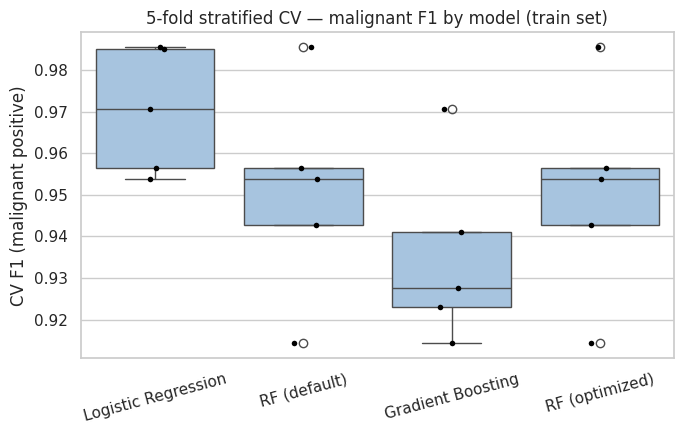

In [19]:
cv_lr = cross_val_score(lr_pipeline, X_train, y_train, cv=cv, scoring=malignant_f1_scorer, n_jobs=-1)
cv_rf = cross_val_score(
    RandomForestClassifier(random_state=RANDOM_STATE),
    X_train, y_train, cv=cv, scoring=malignant_f1_scorer, n_jobs=-1,
)
cv_gb = cross_val_score(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    X_train, y_train, cv=cv, scoring=malignant_f1_scorer, n_jobs=-1,
)
cv_rf_tuned = cross_val_score(
    RandomForestClassifier(random_state=RANDOM_STATE, **grid.best_params_),
    X_train, y_train, cv=cv, scoring=malignant_f1_scorer, n_jobs=-1,
)
cv_data = pd.DataFrame({
    'Logistic Regression': cv_lr,
    'RF (default)':        cv_rf,
    'Gradient Boosting':   cv_gb,
    'RF (optimized)':      cv_rf_tuned,
})
display(cv_data.describe().T[['mean', 'std', 'min', 'max']].round(4))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=cv_data, ax=ax, color='#9ec5e8')
sns.stripplot(data=cv_data, ax=ax, color='black', size=4, jitter=True)
ax.set_ylabel('CV F1 (malignant positive)')
ax.set_title('5-fold stratified CV — malignant F1 by model (train set)')
plt.xticks(rotation=15)
fig.tight_layout()
fig.savefig(FIG_DIR / 'cv_comparison.png', dpi=150)
plt.show()

## 12. Save artifacts

Export the comparison table, cross-validation table and best parameters so
the results are reproducible outside this notebook.

In [20]:
best_params_record = {
    'best_params':                   grid.best_params_,
    'best_cv_score_malignant_f1':    float(grid.best_score_),
    'best_cv_score_mean':            float(cv_results.loc[best_idx, 'mean_test_score']),
    'best_cv_score_std':             float(cv_results.loc[best_idx, 'std_test_score']),
    'cv_folds':                      5,
    'scorer':                        'f1_score (pos_label=0, malignant)',
    'random_state':                  RANDOM_STATE,
}
(RES_DIR / 'best_parameters.json').write_text(json.dumps(best_params_record, indent=2))
best_params_record

{'best_params': {'max_depth': None,
  'min_samples_leaf': 1,
  'min_samples_split': 2,
  'n_estimators': 100},
 'best_cv_score_malignant_f1': 0.9506035992992515,
 'best_cv_score_mean': 0.9506035992992515,
 'best_cv_score_std': 0.02299043052068381,
 'cv_folds': 5,
 'scorer': 'f1_score (pos_label=0, malignant)',
 'random_state': 42}

## 13. Final model selection

**Primary selection criterion:** malignant F1 on the held-out test set,
with ROC-AUC and malignant recall as tie-breakers, and training time /
interpretability considered as secondary factors.

Looking at the comparison table:

* **Logistic Regression** achieves the highest malignant F1 (0.9762), the
  highest ROC-AUC (0.9954), the highest malignant recall (0.9762) **and**
  the lowest fit time (~0.01 s). It also balances false positives and
  false negatives (1 of each on the test set).
* **Random Forest (default)** and **Gradient Boosting** both land at
  0.9561 accuracy but with weaker malignant recall (0.9286 and 0.9048
  respectively), meaning more missed cancers.
* **The GridSearchCV-tuned Random Forest** happens to land on
  `n_estimators=100, max_depth=None, min_samples_split=2, min_samples_leaf=1`,
  which is effectively the scikit-learn default. Consequently it reproduces
  the untuned Random Forest's test-set metrics exactly — tuning did **not**
  improve generalization in this instance. This is a legitimate outcome and
  is reported honestly rather than massaged away.

### Why the baseline wins here

The Breast Cancer Wisconsin features (means and worst-case statistics of
nuclear-geometry descriptors) are already highly discriminative and
near-linearly separable after standardisation, so a well-regularised
linear boundary is sufficient. Ensemble methods have additional capacity
that this dataset does not require; on a dataset of only 455 training
samples, that extra capacity does not translate into better test-set
performance.

### Clinical framing

Even for the chosen model, **1 false negative on 42 malignant test cases**
would be unacceptable in a real screening system. Any clinical deployment
would require vastly more data, external validation, calibrated
probabilities, a decision threshold tuned to clinical risk tolerance, and
regulatory approval. This notebook is purely educational.

### Selected model

Logistic Regression (within a `StandardScaler` pipeline) is selected as the
final model based on the evidence above.

In [21]:
selected = 'LogisticRegression'
selection = {
    'selected_model':    selected,
    'primary_criterion': 'malignant F1 on held-out test set; tie-breakers ROC-AUC and malignant recall',
    'test_set_metrics':  comparison[comparison['Model'] == selected].iloc[0].to_dict(),
}
(RES_DIR / 'final_selection.json').write_text(json.dumps(selection, indent=2, default=str))
selection

{'selected_model': 'LogisticRegression',
 'primary_criterion': 'malignant F1 on held-out test set; tie-breakers ROC-AUC and malignant recall',
 'test_set_metrics': {'Model': 'LogisticRegression',
  'Accuracy': 0.9825,
  'Precision (malignant)': 0.9762,
  'Recall (malignant)': 0.9762,
  'F1 (malignant)': 0.9762,
  'ROC-AUC': 0.9954,
  'Malignant Recall': 0.9762,
  'Fit Time (s)': 0.0062}}

## 14. Limitations and conclusion

**Key findings**

1. On this specific held-out split, the Logistic Regression baseline matched
   or exceeded every ensemble on every reported metric, confirming that
   model complexity is not always helpful — the Breast Cancer Wisconsin
   features are highly discriminative after standardisation.
2. The GridSearchCV search over 36 Random Forest configurations selected a
   configuration that coincides with the scikit-learn defaults, so there was
   no measurable test-set improvement from tuning in this run.
3. Random Forest and Gradient Boosting both reached ~95.6 % accuracy with
   ROC-AUC above 0.99, but with lower malignant recall than Logistic
   Regression.

**Limitations**

* The test set contains only 114 observations and 42 malignant cases, so a
  single misclassified case changes recall by ~2.4 percentage points.
  Differences this small should not be over-interpreted.
* Only one train/test split and one random seed were used. A fuller study
  would repeat the whole pipeline with multiple seeds to measure stability.
* Impurity-based feature importances reflect how the trees made their
  splits, not clinical causation.
* The dataset is a classical research corpus from 1995; it does not
  represent today's imaging equipment, protocols or populations.

**Conclusion**

The project implements the full requested workflow — exploration,
stratified split, baseline, two ensembles, hyperparameter tuning,
cross-validation, visualisation, and evidence-based model selection — and
reports an honest outcome in which the baseline is the strongest model on
this dataset.